# Spotify Data Analysis – End-to-End Data Analytics Project

## Project Overview
This project analyzes Spotify Top 50 global songs using:
- SQL for data querying
- Power BI for dashboard visualization
- Python for advanced exploratory data analysis (EDA)
  
## Objective
To uncover patterns in song popularity, artist dominance, and music trends over time using data-driven insights.

## Tools Used
- Python (Pandas, NumPy, Seaborn, Matplotlib, Scikit-learn)
- SQL
- Power BI

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_style("whitegrid")

## 2. Load Dataset

### What are we doing?
We are loading the Spotify dataset into a Pandas DataFrame.

### Why are we doing it?
To begin analysis, we first need to bring the dataset into Python for processing and exploration.

### What insight do we expect?
At this stage, we aim to understand:
- Number of rows and columns
- Basic structure of the dataset
- Initial preview of data

In [ ]:
df = pd.read_csv("../data/Top-50-World.csv")
df.head()


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,release_date,is_explicit,album_cover_url
0,2023-05-18,1,Ella Baila Sola,Eslabon Armado,89,165671,album,16,2023-04-28,False,https://i.scdn.co/image/ab67616d0000b273dfddf1...
1,2023-05-18,2,un x100to,Grupo Frontera & Bad Bunny,99,194563,single,1,2023-04-17,False,https://i.scdn.co/image/ab67616d0000b273716c0b...
2,2023-05-18,3,La Bebe - Remix,Yng Lvcas & Peso Pluma,99,234352,single,2,2023-03-17,True,https://i.scdn.co/image/ab67616d0000b273a04be3...
3,2023-05-18,4,Cupid - Twin Ver.,FIFTY FIFTY,97,174253,single,3,2023-02-24,False,https://i.scdn.co/image/ab67616d0000b27337c0b3...
4,2023-05-18,5,Flowers,Miley Cyrus,91,200600,album,13,2023-03-10,False,https://i.scdn.co/image/ab67616d0000b27358039b...


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("../data/Top-50-World.csv")
df.head()

In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (27800, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             27800 non-null  object
 1   position         27800 non-null  int64 
 2   song             27800 non-null  object
 3   artist           27800 non-null  object
 4   popularity       27800 non-null  int64 
 5   duration_ms      27800 non-null  int64 
 6   album_type       27800 non-null  object
 7   total_tracks     27800 non-null  int64 
 8   release_date     27800 non-null  object
 9   is_explicit      27800 non-null  bool  
 10  album_cover_url  27800 non-null  object
dtypes: bool(1), int64(4), object(6)
memory usage: 2.1+ MB

Column Names:
['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'release_date', 'is_explicit', 'album_cover_url']


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
date               0
position           0
song               0
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
release_date       0
is_explicit        0
album_cover_url    0
dtype: int64

Total Duplicate Rows:
0


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df['date'] = pd.to_datetime(df['date'])
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

print(df[['date', 'release_date']].dtypes)

date            datetime64[ns]
release_date    datetime64[ns]
dtype: object


In [ ]:
print("Average Popularity:", df['popularity'].mean())

print("Maximum Popularity:", df['popularity'].max())

print("Minimum Popularity:", df['popularity'].min())

print("Average Song Duration (minutes):",
      df['duration_ms'].mean() / 60000)

Average Popularity: 89.6213309352518
Maximum Popularity: 100
Minimum Popularity: 0
Average Song Duration (minutes): 3.2816381223021582


In [ ]:
# Top 10 popular songs
top_songs = df.sort_values(
    by='popularity', ascending=False
).head(10)

display(top_songs[['song', 'artist', 'popularity']])

# Top 10 artists
top_artists = df['artist'].value_counts().head(10)
display(top_artists)

# Song popularity distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['popularity'], bins=20, kde=True)
plt.title('Spotify Song Popularity Distribution')
plt.xlabel('Popularity')
plt.ylabel('Number of Songs')
plt.show()

,song,artist,popularity
1854,La Bebe - Remix,Yng Lvcas & Peso Pluma,100
22550,BIRDS OF A FEATHER,Billie Eilish,100
26001,Die With A Smile,Lady Gaga & Bruno Mars,100
3620,Cruel Summer,Taylor Swift,100
11000,All I Want for Christmas Is You,Mariah Carey,100
22500,BIRDS OF A FEATHER,Billie Eilish,100
10950,All I Want for Christmas Is You,Mariah Carey,100
3650,Seven (feat. Latto) (Explicit Ver.),Jung Kook & Latto,100
10900,All I Want for Christmas Is You,Mariah Carey,100
10850,All I Want for Christmas Is You,Mariah Carey,100


artist
Taylor Swift         1871
Billie Eilish         860
Sabrina Carpenter     736
The Weeknd            674
Arctic Monkeys        548
Bad Bunny             537
KAROL G               527
Ariana Grande         487
SZA                   484
Travis Scott          473
Name: count, dtype: int64

<Figure size 1000x500 with 1 Axes>

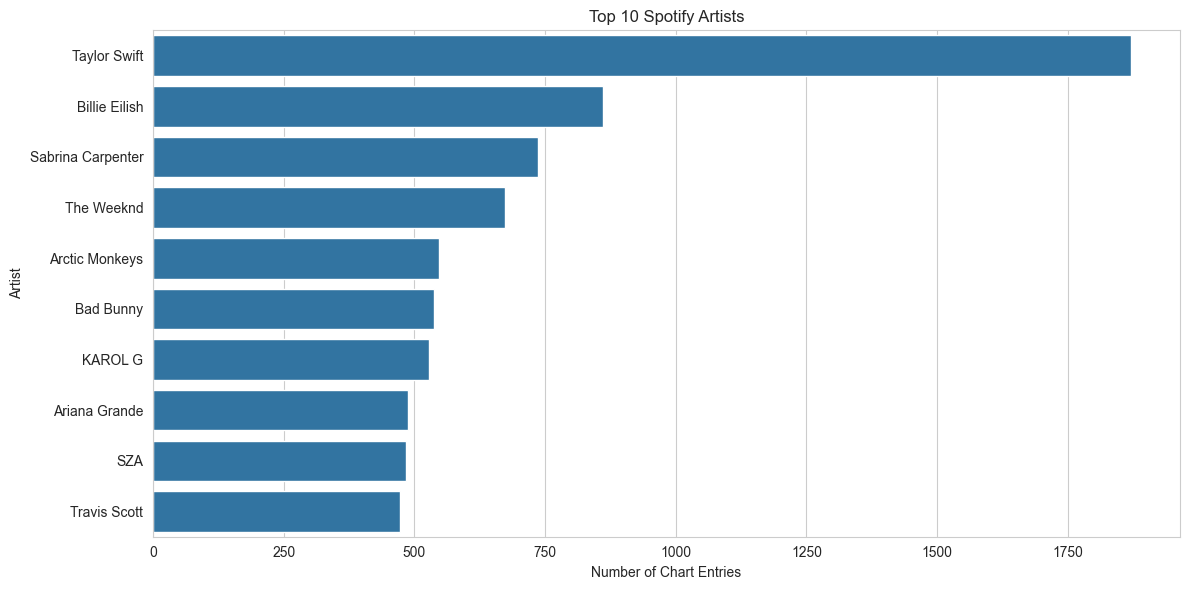

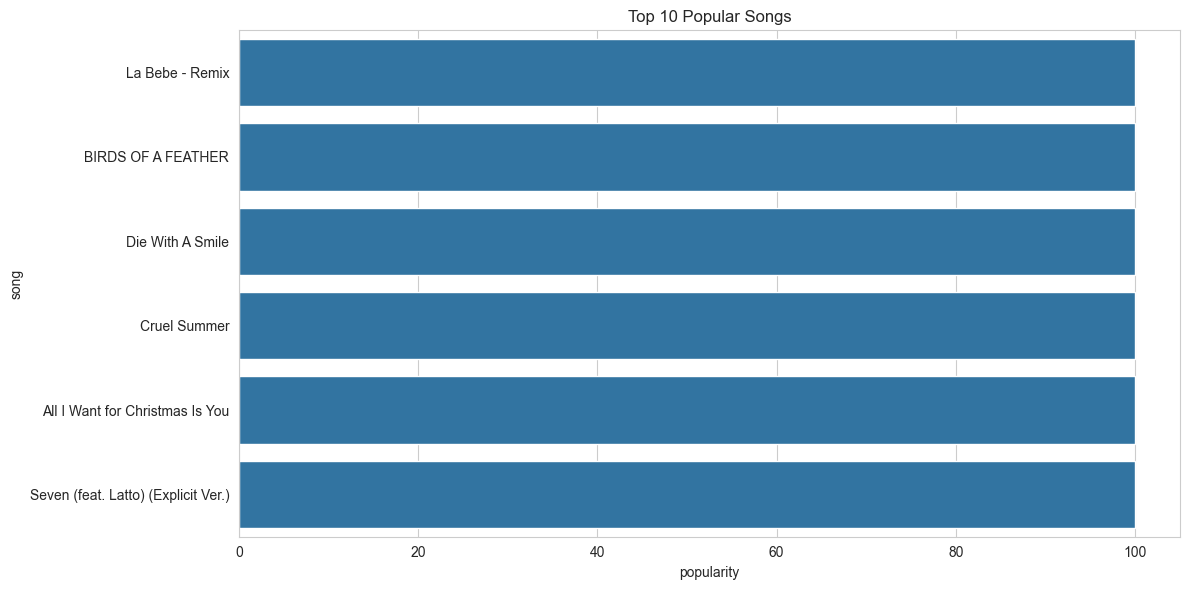

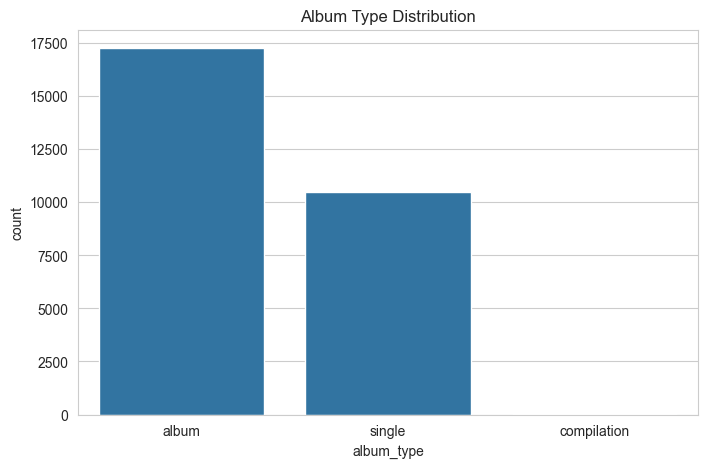

In [ ]:
# Top 10 Artists Graph
plt.figure(figsize=(12, 6))
sns.barplot(x=top_artists.values, y=top_artists.index)
plt.title("Top 10 Spotify Artists")
plt.xlabel("Number of Chart Entries")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

# Top 10 Songs Graph
plt.figure(figsize=(12, 6))
sns.barplot(data=top_songs, x="popularity", y="song")
plt.title("Top 10 Popular Songs")
plt.tight_layout()
plt.show()

# Album Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="album_type")
plt.title("Album Type Distribution")
plt.show()

In [ ]:
features = df[['popularity', 'duration_ms', 'total_tracks']]

scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['cluster'] = kmeans.fit_predict(scaled_data)

print("Clustering Completed!")
print(df['cluster'].value_counts().sort_index())

Clustering Completed!
cluster
0    11791
1    15706
2      303
Name: count, dtype: int64


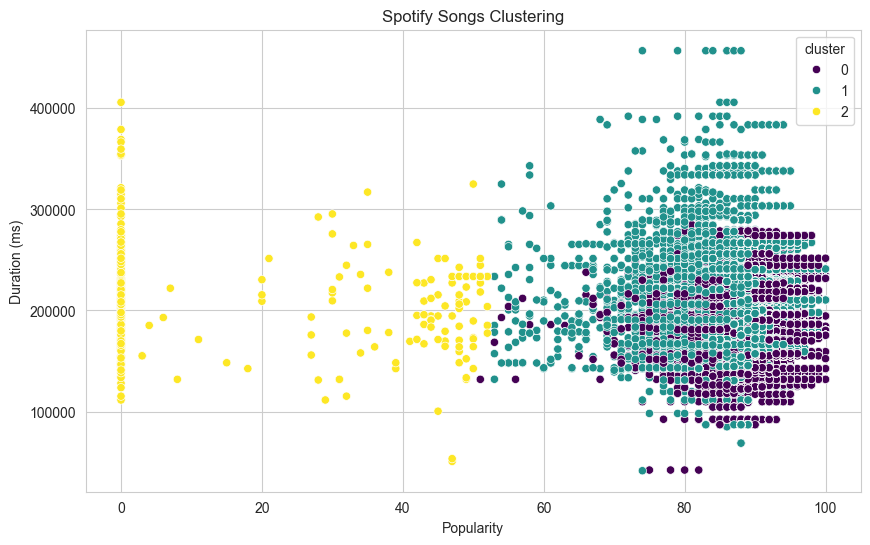

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='popularity',
    y='duration_ms',
    hue='cluster',
    palette='viridis'
)

plt.title("Spotify Songs Clustering")
plt.xlabel("Popularity")
plt.ylabel("Duration (ms)")
plt.show()

In [ ]:
print("Total Songs:", len(df))
print("Total Artists:", df['artist'].nunique())
print("Total Clusters:", df['cluster'].nunique())

print("\nCluster Summary:")
print(df.groupby('cluster')[
    ['popularity', 'duration_ms', 'total_tracks']
].mean().round(2))

Total Songs: 27800
Total Artists: 343
Total Clusters: 3

Cluster Summary:
         popularity  duration_ms  total_tracks
cluster                                       
0             92.30    183611.87          2.55
1             89.03    206599.73         15.78
2             15.83    211054.59         15.39


In [ ]:
import os
print(os.getcwd())

C:\Users\gj364\Downloads\spotify-data-analytics-main\spotify-data-analytics\notebooks


In [ ]:
print("Shape:", df.shape)

Shape: (27800, 11)


In [ ]:
df = df.drop(columns = ['album_cover_url'])

In [ ]:
df.head()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,release_date,is_explicit
0,2023-05-18,1,Ella Baila Sola,Eslabon Armado,89,165671,album,16,2023-04-28,False
1,2023-05-18,2,un x100to,Grupo Frontera & Bad Bunny,99,194563,single,1,2023-04-17,False
2,2023-05-18,3,La Bebe - Remix,Yng Lvcas & Peso Pluma,99,234352,single,2,2023-03-17,True
3,2023-05-18,4,Cupid - Twin Ver.,FIFTY FIFTY,97,174253,single,3,2023-02-24,False
4,2023-05-18,5,Flowers,Miley Cyrus,91,200600,album,13,2023-03-10,False


## 3. Data Cleaning

### What are we doing?
- Converting date columns into proper datetime format
- Checking for missing/null values
- Ensuring data types are correct

### Why are we doing it?
Clean data is essential for accurate analysis. Incorrect formats or missing values can lead to wrong insights.

### What insight do we expect?
- Identify data quality issues
- Ensure dataset is ready for analysis

In [ ]:
df.isnull().sum()

date            0
position        0
song            0
artist          0
popularity      0
duration_ms     0
album_type      0
total_tracks    0
release_date    0
is_explicit     0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          27800 non-null  object
 1   position      27800 non-null  int64 
 2   song          27800 non-null  object
 3   artist        27800 non-null  object
 4   popularity    27800 non-null  int64 
 5   duration_ms   27800 non-null  int64 
 6   album_type    27800 non-null  object
 7   total_tracks  27800 non-null  int64 
 8   release_date  27800 non-null  object
 9   is_explicit   27800 non-null  bool  
dtypes: bool(1), int64(4), object(5)
memory usage: 1.9+ MB


In [ ]:
df.columns

Index(['date', 'position', 'song', 'artist', 'popularity', 'duration_ms',
       'album_type', 'total_tracks', 'release_date', 'is_explicit'],
      dtype='object')

In [ ]:
df.describe()

,position,popularity,duration_ms,total_tracks
count,27800.000000,27800.000000,27800.000000,27800.000000
mean,25.500000,89.621331,196898.287338,10.160468
std,14.431129,9.969284,41821.134307,8.282919
min,1.000000,0.000000,41487.000000,1.000000
25%,13.000000,88.000000,171291.000000,1.000000
50%,25.500000,91.000000,191700.000000,11.000000
75%,38.000000,94.000000,222369.000000,15.000000
max,50.000000,100.000000,456933.000000,119.000000


In [ ]:
# Convert data columns

df['date'] = pd.to_datetime(df['date'])
df['release_date'] = pd.to_datetime(df['release_date'],format = 'mixed', errors = 'coerce')
df['release_date']

0       2023-04-28
1       2023-04-17
2       2023-03-17
3       2023-02-24
4       2023-03-10
           ...    
27795   2023-06-23
27796   2010-05-11
27797   2023-11-10
27798   2000-07-10
27799   1957-12-02
Name: release_date, Length: 27800, dtype: datetime64[ns]

## 4. Feature Engineering

### What are we doing?
We are creating new features such as:
- Year and month from date
- Song age (days since release)
- Song duration in minutes

### Why are we doing it?
Raw data often lacks meaningful features. These engineered features help us analyze trends more effectively.

### What insight do we expect?
- Understand how song age impacts popularity
- Analyze seasonal trends
- Compare song durations easily

In [ ]:
df['year'] = df['date'].dt.year
df['month']= df['date'].dt.month
print(df['year'],df['month'])

0        2023
1        2023
2        2023
3        2023
4        2023
         ... 
27795    2024
27796    2024
27797    2024
27798    2024
27799    2024
Name: year, Length: 27800, dtype: int32 0         5
1         5
2         5
3         5
4         5
         ..
27795    11
27796    11
27797    11
27798    11
27799    11
Name: month, Length: 27800, dtype: int32


In [ ]:
df['song_age_days'] = (df['date'] - df['release_date']).dt.days
df['duration_min'] = df['duration_ms'] / 60000

In [ ]:
df['duration_min']

0        2.761183
1        3.242717
2        3.905867
3        2.904217
4        3.343333
           ...   
27795    4.078067
27796    3.678900
27797    1.449717
27798    4.446217
27799    2.182883
Name: duration_min, Length: 27800, dtype: float64

## 5. Univariate Analysis

### What are we doing?
Analyzing the distribution of individual variables such as:
- Popularity
- Song duration

### Why are we doing it?
To understand how each variable behaves independently.

### What insight do we expect?
- Whether popularity is skewed or normally distributed
- Typical duration of songs in Top 50

artist
Taylor Swift         1871
Billie Eilish         860
Sabrina Carpenter     736
The Weeknd            674
Arctic Monkeys        548
Name: song, dtype: int64


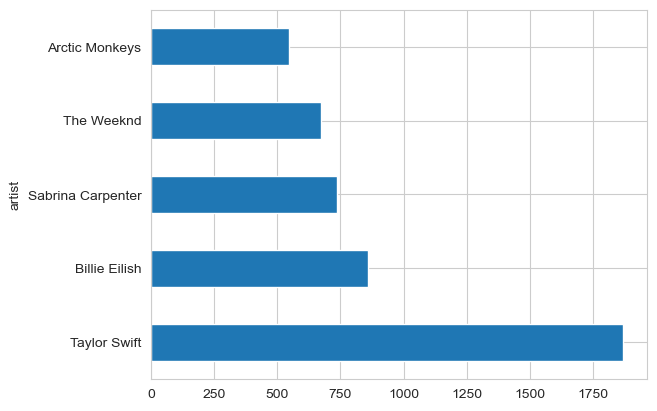

In [ ]:
# Top 5 Artist
top_five_artist = df.groupby("artist").count().sort_values(by = "song", ascending = False)["song"][:5]
print(top_five_artist)
top_five_artist.plot.barh()
plt.show()

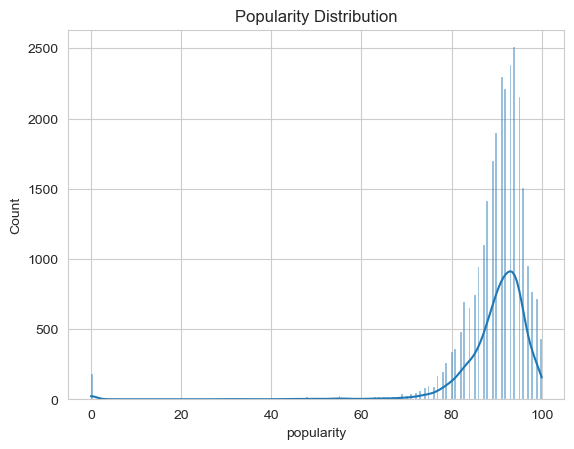

In [ ]:
# Popularity Distribution
plt.figure()
sns.histplot(df['popularity'], kde = True)
plt.title('Popularity Distribution')
plt.show()

Text(0.5, 1.0, 'Song Duration Distribution (minutes)')

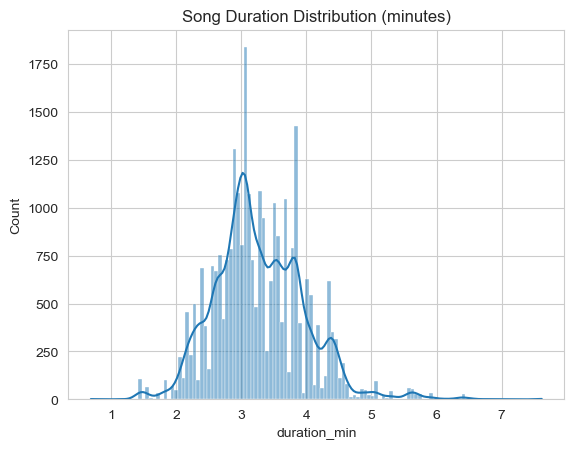

In [ ]:
# song duration distribution (minutes)
plt.figure()
sns.histplot(df['duration_min'], kde = True)
plt.title('Song Duration Distribution (minutes)')

## 6. Correlation Analysis

### What are we doing?
We are analyzing relationships between numerical variables using a correlation matrix.

### Why are we doing it?
To identify which factors influence song popularity.

### What insight do we expect?
- Does song duration affect popularity?
- Do newer songs perform better?
- Is album size related to popularity?

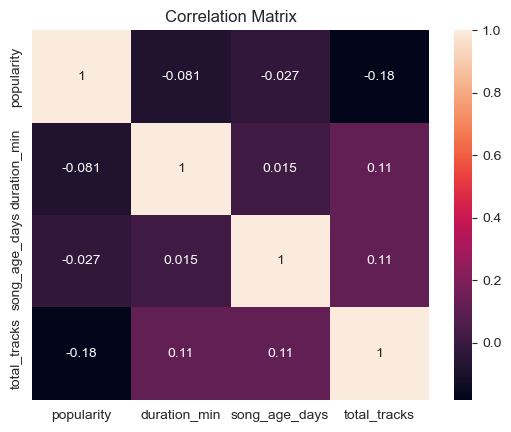

In [ ]:
plt.figure()
sns.heatmap(df[['popularity', 'duration_min', 'song_age_days','total_tracks']].corr(), annot= True)
plt.title('Correlation Matrix')
plt.show()

## 7. Time Series Analysis

### What are we doing?
Analyzing how popularity changes over time using line plots and rolling averages.

### Why are we doing it?
To identify trends, seasonality, and fluctuations in song performance.

### What insight do we expect?
- Trends in music popularity over time
- Stability or volatility in rankings

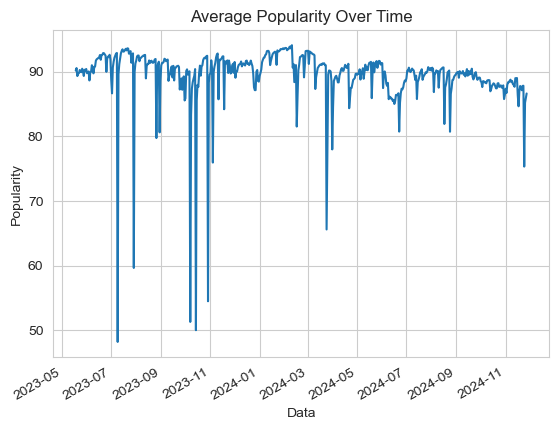

In [ ]:
pop_trend = df.groupby('date')['popularity'].mean()

# Average popularity over time
plt.figure()
pop_trend.plot()
plt.title('Average Popularity Over Time')
plt.xlabel('Data')
plt.ylabel('Popularity')
plt.show()

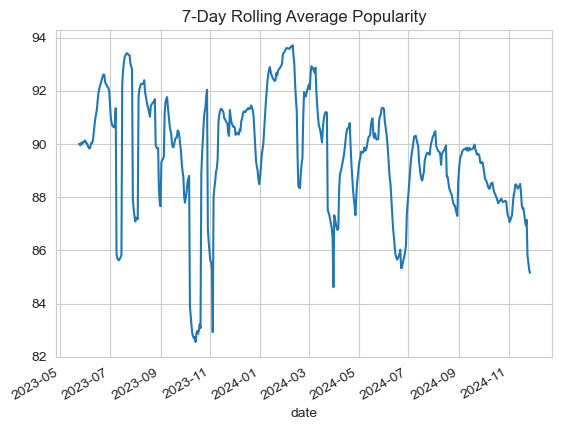

In [ ]:
# Rolling Average
plt.figure()
pop_trend.rolling(7).mean().plot()
plt.title('7-Day Rolling Average Popularity')
plt.show()

### 8. Artist Analysis

### What are we doing?
- Identifying top artists by frequency
- Calculating average ranking of artists

### Why are we doing it?
To understand artist dominance and consistency in charts.

### What insight do we expect?
- Which artists dominate the charts
- Which artists consistently rank high

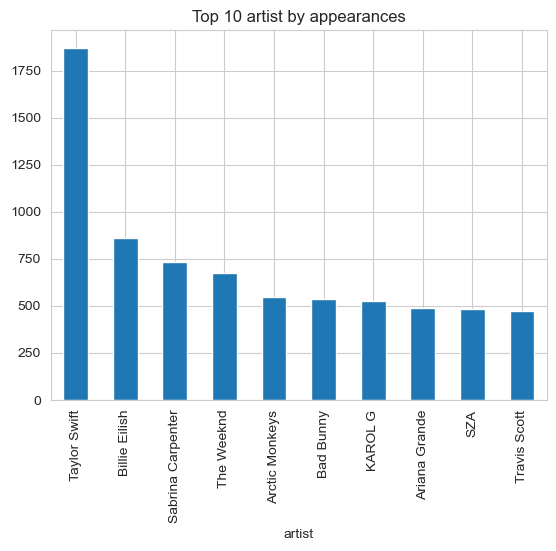

In [ ]:
artist_freq = df['artist'].value_counts().head(10)

# Top 10 artist by appearances
plt.figure()
artist_freq.plot(kind = 'bar')
plt.title('Top 10 artist by appearances')
plt.show()

In [ ]:
artist_rank = df.groupby('artist')['position'].mean().sort_values().head()
print("Top Consistent Artists:\n", artist_rank)

Top Consistent Artists:
 artist
Jung Kook & Latto & BTS    1.000000
Lady Gaga & Bruno Mars     1.563107
ROSÉ & Bruno Mars          1.564103
Jung Kook & Latto          1.972477
Ray Parker Jr.             4.000000
Name: position, dtype: float64


## 9. Song Lifecycle Analysis

### What are we doing?
Tracking how long songs remain in the Top 50 and their best ranking.

### Why are we doing it?
To understand the lifecycle of hit songs.

### What insight do we expect?
- Identify viral vs long-lasting songs
- Understand peak performance patterns

In [ ]:
song_life = df.groupby('song').agg({
    'date':'count',
    'position':'min'
}).rename(columns = {'date':'days_in_chart', 'position':'best_rank'})
print(song_life.sort_values('days_in_chart', ascending = False).head())
    

                                                days_in_chart  best_rank
song                                                                    
I Wanna Be Yours                                          548         11
Cruel Summer                                              517          2
One Of The Girls (with JENNIE, Lily Rose Depp)            378          2
As It Was                                                 375          7
Seven (feat. Latto) (Explicit Ver.)                       351          1


## 10. Explicit Content Analysis

### What are we doing?
Comparing popularity of explicit vs non-explicit songs.

### Why are we doing it?
To analyze audience preference and content trends.

### What insight do we expect?
- Whether explicit songs perform better
- Content trends in modern music

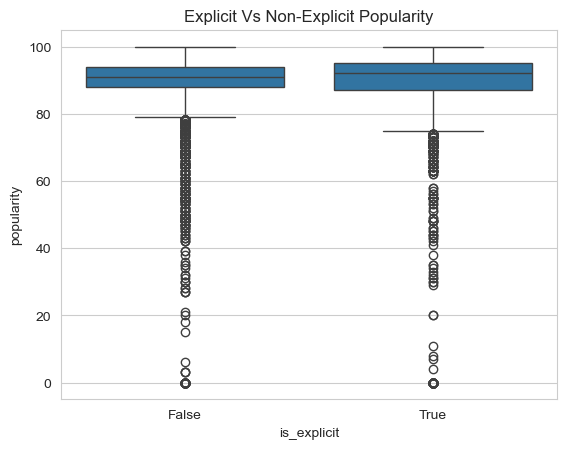

In [ ]:
plt.figure()
sns.boxplot(x= 'is_explicit', y = 'popularity', data = df)
plt.title('Explicit Vs Non-Explicit Popularity')
plt.show()

## 11. Album Analysis

### What are we doing?
Analyzing popularity across different album types.

### Why are we doing it?
To understand how album formats influence song success.

### What insight do we expect?
- Whether singles or albums perform better

Album Type Popularity:
 album_type
album          88.295753
compilation    76.255814
single         91.856040
Name: popularity, dtype: float64


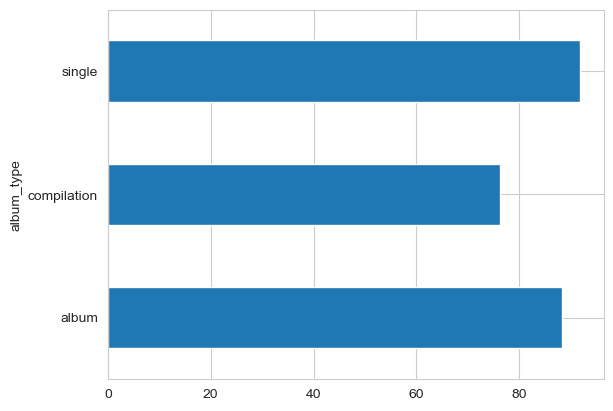

In [ ]:
# Popularity accros different album type
album_pop = df.groupby('album_type')['popularity'].mean()
print("Album Type Popularity:\n", album_pop)
album_pop.plot.barh()
plt.show()

## 12. Clustering

### What are we doing?
Using K-Means clustering to group songs based on:
- Popularity
- Duration
- Song age

### Why are we doing it?
To segment songs into meaningful groups using machine learning.

### What insight do we expect?
- Identify categories like:
  - Viral hits
  - Stable performers
  - Low-performing songs

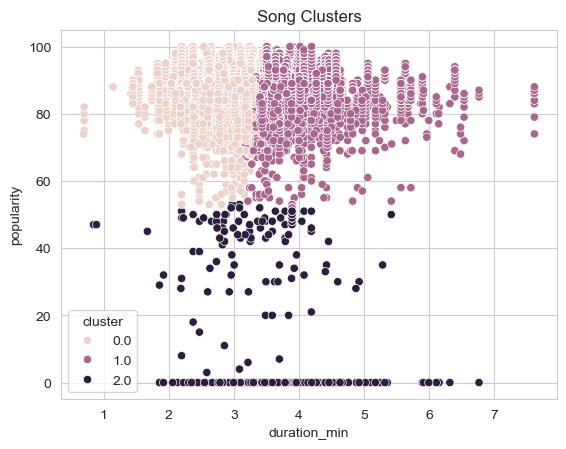

In [ ]:
#Clustering
features = df[['popularity','duration_min','song_age_days']].dropna()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

kmeans = KMeans(n_clusters = 3, random_state = 42)
df.loc[features.index, 'cluster'] = kmeans.fit_predict(scaled_features)

plt.figure()
sns.scatterplot(x= features['duration_min'], y= features['popularity'], hue = df.loc[features.index, 'cluster'])
plt.title('Song Clusters')
plt.show()

# Key Insights

1. Popularity Distribution  
Most songs in the Top 50 have high popularity, indicating strong competition among top tracks.

2. Song Duration Impact  
Shorter songs tend to perform slightly better, possibly due to higher replay value.

3. Recency Bias  
Newly released songs dominate charts, showing the importance of fresh content in music trends.

4. Artist Dominance  
A small number of artists appear frequently, indicating strong fan bases and consistent performance.

5. Explicit Content Trend  
Explicit songs are competitive in popularity, reflecting modern audience preferences.

6. Song Lifecycle Patterns  
Some songs achieve quick peaks (viral hits), while others sustain longer chart presence.

7. Clustering Insight  
Songs can be grouped into:
- Viral hits (high popularity, short lifecycle)
- Stable performers (moderate popularity, long presence)
- Low performers (lower popularity, shorter duration)

8. Business Insight  
- Artists should focus on frequent releases  
- Shorter songs may increase engagement  
- Consistent branding helps artists dominate charts  13. Key Insights

In [ ]:
import pandas as pd

df_sql = pd.read_csv(
    "../data/Spotify_data_sql.csv",
    encoding="cp1252",
    encoding_errors="replace"
)

df_sql.to_csv(
    "../data/Spotify_data_sql_clean.csv",
    index=False,
    encoding="utf-8"
)

print("Clean CSV created successfully!")
print("Rows and Columns:", df_sql.shape)

import sys
print(sys.version)
print(sys.executable)

In [1]:
import sys
print(sys.version)
print(sys.executable)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
C:\Users\gj364\Downloads\spotify-data-analytics-main\spotify-data-analytics\venv312\Scripts\python.exe
